<a href="https://colab.research.google.com/github/noahchen3/ds4420-bankruptcy-prediction/blob/main/modeling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("data.csv")
df.columns = df.columns.str.strip()   # some column names have leading spaces
print(df.shape)
print(df["Bankrupt?"].value_counts())
print("Total missing values:", df.isna().sum().sum())

(6819, 96)
Bankrupt?
0    6599
1     220
Name: count, dtype: int64
Total missing values: 0


In [2]:
const_cols = [c for c in df.columns if df[c].nunique() == 1]
print("Constant columns:", const_cols)

ranges = df.describe().T[["min", "max"]]
print(ranges.sort_values("max", ascending=False).head(10))

Constant columns: ['Net Income Flag']
                                       min           max
Cash Turnover Rate                     0.0  1.000000e+10
Current Asset Turnover Rate            0.0  1.000000e+10
Quick Asset Turnover Rate              0.0  1.000000e+10
Operating Expense Rate                 0.0  9.990000e+09
Fixed Assets Turnover Frequency        0.0  9.990000e+09
Total Asset Growth Rate                0.0  9.990000e+09
Inventory Turnover Rate (times)        0.0  9.990000e+09
Research and development expense rate  0.0  9.980000e+09
Total debt/Total net worth             0.0  9.940000e+09
Inventory/Current Liability            0.0  9.910000e+09


In [3]:
df = df.drop(columns=["Net Income Flag"])
feature_names = df.drop(columns=["Bankrupt?"]).columns.tolist()
X, y = df[feature_names].values, df["Bankrupt?"].values

rng = np.random.default_rng(42)
test_idx = np.concatenate([rng.choice(np.where(y == k)[0], int(0.2 * (y == k).sum()), replace=False) for k in [0, 1]])
train_idx = np.setdiff1d(np.arange(len(y)), test_idx)
X_train, X_test, y_train, y_test = X[train_idx], X[test_idx], y[train_idx], y[test_idx]
print(X_train.shape, X_test.shape, y_train.mean().round(4), y_test.mean().round(4))

(5456, 94) (1363, 94) 0.0323 0.0323


In [4]:
lo, hi = np.percentile(X_train, [1, 99], axis=0)
binary = np.array([len(np.unique(X_train[:, j])) <= 2 for j in range(X_train.shape[1])])
lo[binary], hi[binary] = X_train[:, binary].min(0), X_train[:, binary].max(0)

X_train_c, X_test_c = np.clip(X_train, lo, hi), np.clip(X_test, lo, hi)
mu, sd = X_train_c.mean(axis=0), X_train_c.std(axis=0)
sd[sd == 0] = 1.0
X_train_s, X_test_s = (X_train_c - mu) / sd, (X_test_c - mu) / sd
print(np.abs(X_train_s).max().round(2), np.abs(X_test_s).max().round(2))

33.02 33.02


In [5]:
bayes_feats = ["ROA(A) before interest and % after tax", "Debt ratio %",
               "Working Capital to Total Assets", "Retained Earnings to Total Assets",
               "Cash Flow to Total Assets", "Total Asset Turnover",
               "Current Ratio", "Borrowing dependency"]
print("Missing:", [f for f in bayes_feats if f not in feature_names])
idx = [feature_names.index(f) for f in bayes_feats]
Xb_train, Xb_test = X_train_s[:, idx], X_test_s[:, idx]
print(pd.DataFrame(Xb_train, columns=bayes_feats).corr().round(2))

Missing: []
                                        ROA(A) before interest and % after tax  \
ROA(A) before interest and % after tax                                    1.00   
Debt ratio %                                                             -0.25   
Working Capital to Total Assets                                           0.31   
Retained Earnings to Total Assets                                         0.82   
Cash Flow to Total Assets                                                 0.27   
Total Asset Turnover                                                      0.25   
Current Ratio                                                             0.13   
Borrowing dependency                                                     -0.32   

                                        Debt ratio %  \
ROA(A) before interest and % after tax         -0.25   
Debt ratio %                                    1.00   
Working Capital to Total Assets                -0.51   
Retained Earnings to Tota

In [6]:
import pymc as pm   # if this errors, run: !pip install pymc
import arviz as az

with pm.Model() as bayes_lr:
    b0 = pm.Normal("intercept", mu=0, sigma=2.5)
    w = pm.Normal("w", mu=0, sigma=1, shape=len(bayes_feats))
    p = pm.math.sigmoid(b0 + pm.math.dot(Xb_train, w))
    pm.Bernoulli("y_obs", p=p, observed=y_train)
    trace = pm.sample(1000, tune=1000, chains=2, random_seed=42)

print(az.summary(trace, var_names=["intercept", "w"]).round(3))

Output()

            mean     sd  hdi_3%  hdi_97%  mcse_mean  mcse_sd  ess_bulk  \
intercept -5.065  0.186  -5.412   -4.727      0.005    0.004    1576.0   
w[0]      -0.710  0.143  -0.963   -0.425      0.003    0.003    1694.0   
w[1]       1.019  0.196   0.661    1.397      0.006    0.004    1251.0   
w[2]      -0.163  0.152  -0.444    0.124      0.004    0.003    1594.0   
w[3]      -0.271  0.118  -0.496   -0.055      0.003    0.003    1683.0   
w[4]      -0.222  0.115  -0.444   -0.007      0.002    0.003    2134.0   
w[5]      -0.411  0.111  -0.611   -0.202      0.003    0.002    1749.0   
w[6]      -0.106  0.291  -0.666    0.417      0.008    0.007    1416.0   
w[7]       0.164  0.103  -0.016    0.378      0.003    0.002    1414.0   

           ess_tail  r_hat  
intercept    1462.0    1.0  
w[0]         1451.0    1.0  
w[1]         1383.0    1.0  
w[2]         1312.0    1.0  
w[3]         1243.0    1.0  
w[4]         1385.0    1.0  
w[5]         1371.0    1.0  
w[6]         1152.0    1.0 

In [7]:
from sklearn.metrics import roc_auc_score, f1_score, recall_score, precision_score, confusion_matrix

post = az.extract(trace)
b0_s, w_s = post["intercept"].values, post["w"].values      # (draws,), (8, draws)
def post_prob(Xm): return (1 / (1 + np.exp(-(b0_s + Xm @ w_s)))).mean(axis=1)
p_train_b, p_test_b = post_prob(Xb_train), post_prob(Xb_test)

ths = np.linspace(0.01, 0.5, 50)
best_t = ths[np.argmax([f1_score(y_train, p_train_b >= t) for t in ths])]
yhat_b = p_test_b >= best_t
print(f"thr={best_t:.3f} AUC={roc_auc_score(y_test, p_test_b):.3f} recall={recall_score(y_test, yhat_b):.3f} "
      f"precision={precision_score(y_test, yhat_b):.3f} F1={f1_score(y_test, yhat_b):.3f}")
print(confusion_matrix(y_test, yhat_b))

thr=0.170 AUC=0.939 recall=0.591 precision=0.361 F1=0.448
[[1273   46]
 [  18   26]]


In [8]:
summ = az.summary(trace, var_names=["w"], hdi_prob=0.95)
coef = pd.DataFrame({"feature": bayes_feats, "mean": summ["mean"].values,
                     "hdi_2.5%": summ["hdi_2.5%"].values, "hdi_97.5%": summ["hdi_97.5%"].values})
coef["odds_ratio"] = np.exp(coef["mean"])
print(coef.round(3).to_string(index=False))

                               feature   mean  hdi_2.5%  hdi_97.5%  odds_ratio
ROA(A) before interest and % after tax -0.710    -0.985     -0.422       0.492
                          Debt ratio %  1.019     0.639      1.407       2.770
       Working Capital to Total Assets -0.163    -0.464      0.124       0.850
     Retained Earnings to Total Assets -0.271    -0.497     -0.035       0.763
             Cash Flow to Total Assets -0.222    -0.438      0.015       0.801
                  Total Asset Turnover -0.411    -0.628     -0.202       0.663
                         Current Ratio -0.106    -0.666      0.462       0.899
                  Borrowing dependency  0.164    -0.027      0.385       1.178


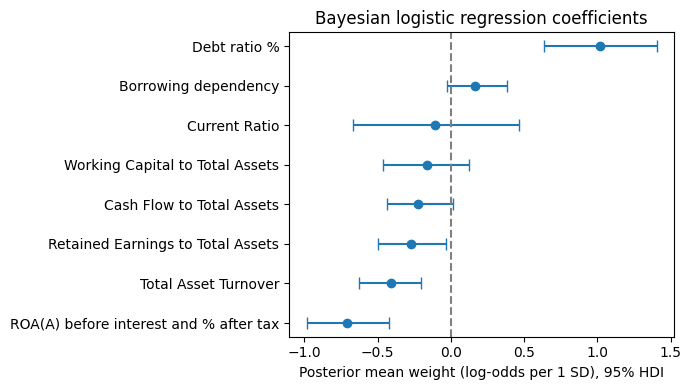

In [9]:
import matplotlib.pyplot as plt
c = coef.sort_values("mean").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(c["mean"], c.index, xerr=[c["mean"] - c["hdi_2.5%"], c["hdi_97.5%"] - c["mean"]], fmt="o", capsize=4)
ax.axvline(0, color="gray", ls="--")
ax.set_yticks(c.index, c["feature"])
ax.set_xlabel("Posterior mean weight (log-odds per 1 SD), 95% HDI")
ax.set_title("Bayesian logistic regression coefficients")
plt.tight_layout(); plt.savefig("bayes_coefficients.png", dpi=200); plt.show()

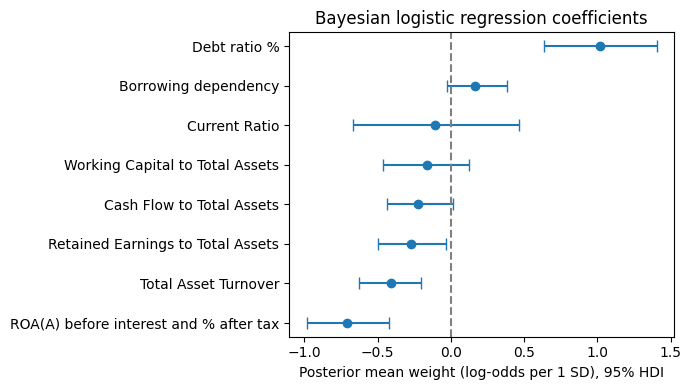

In [10]:
import matplotlib.pyplot as plt
c = coef.sort_values("mean").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(c["mean"], c.index, xerr=[c["mean"] - c["hdi_2.5%"], c["hdi_97.5%"] - c["mean"]], fmt="o", capsize=4)
ax.axvline(0, color="gray", ls="--")
ax.set_yticks(c.index, c["feature"])
ax.set_xlabel("Posterior mean weight (log-odds per 1 SD), 95% HDI")
ax.set_title("Bayesian logistic regression coefficients")
plt.tight_layout(); plt.savefig("bayes_coefficients.png", dpi=200); plt.show()

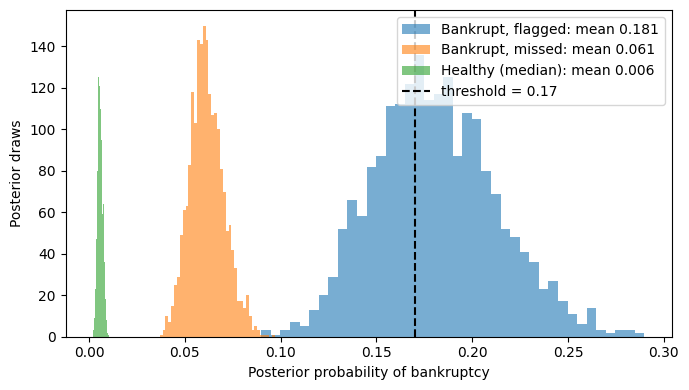

In [11]:
theta_test = 1 / (1 + np.exp(-(b0_s + Xb_test @ w_s)))       # (n_test, draws)
caught = np.where((y_test == 1) & yhat_b)[0][0]
missed = np.where((y_test == 1) & ~yhat_b)[0][0]
h = np.where(y_test == 0)[0]; typical = h[np.argsort(p_test_b[h])[len(h) // 2]]
fig, ax = plt.subplots(figsize=(7, 4))
for i, lab in [(caught, "Bankrupt, flagged"), (missed, "Bankrupt, missed"), (typical, "Healthy (median)")]:
    ax.hist(theta_test[i], bins=40, alpha=0.6, label=f"{lab}: mean {theta_test[i].mean():.3f}")
ax.axvline(best_t, color="k", ls="--", label=f"threshold = {best_t:.2f}")
ax.set_xlabel("Posterior probability of bankruptcy"); ax.set_ylabel("Posterior draws"); ax.legend()
plt.tight_layout(); plt.savefig("bayes_posterior_probs.png", dpi=200); plt.show()